# **Preparation Notebook**

---
## Setup Environment

In [1]:
# DO NOT MODIFY THE CODE IN THIS CELL
!pip install -q utstd
from utstd.folders import *
from utstd.ipyrenders import *
at = AtFolder(course_code=36106, assignment='AT3')
at.run()
import warnings
warnings.simplefilter(action='ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 53.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.42 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
Mounted at /content/gdrive

You can now save your data files in: /content/gdrive/MyDrive/36106/assignment/AT3/data


---
## Student Information

In [2]:
group_name = "Neural Minds"
student_name = "Pal Patel"
student_id = "26173702"

In [3]:
# Do not modify
print_tile(size='h1', key='group_name', value=group_name)

In [4]:
# Do not modify
print_tile(size='h1', key='student_name', value=student_name)

In [5]:
# Do not modify
print_tile(size='h1', key='student_id', value=student_id)

---
## 0. Python Packages

### 0.a Install Additional Packages

In [6]:
!pip install -q scikit-learn

### 0.b Import Packages

In [7]:
# DO NOT MODIFY THE CODE IN THIS CELL
import pandas as pd
import altair as alt

In [8]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

---
## A. Feature Selection

## A.0 Load Data

In [9]:
# DO NOT MODIFY THE CODE IN THIS CELL
try:
    product_cost_history_df       = pd.read_csv(at.folder_path / 'product_cost_history.csv')
    product_list_price_history_df = pd.read_csv(at.folder_path / 'product_list_price_history.csv')
    special_offer_product_df      = pd.read_csv(at.folder_path / 'special_offer_product.csv')
    special_offer_df              = pd.read_csv(at.folder_path / 'special_offer.csv')
    sales_territory_df            = pd.read_csv(at.folder_path / 'sales_territory.csv')
    print('All datasets loaded.')
except Exception as e:
    print(e)

All datasets loaded.


### A.1 Approach 1 - Domain Knowledge Feature Selection

In [10]:
# Aggregate cost features per product
cost_agg = product_cost_history_df.groupby('product_id')['standard_cost'].agg(
    avg_cost='mean', max_cost='max', min_cost='min',
    cost_std='std', cost_periods='count'
).reset_index()
cost_agg['cost_std']    = cost_agg['cost_std'].fillna(0)
cost_agg['cost_change'] = cost_agg['max_cost'] - cost_agg['min_cost']
print('Cost features shape:', cost_agg.shape)
cost_agg.head()

Cost features shape: (293, 7)


,product_id,avg_cost,max_cost,min_cost,cost_std,cost_periods,cost_change
0,001a3a89-15cc-435e-89e5-0c844f44f595,30.9334,30.9334,30.9334,0.000000,1,0.000
1,0025c2c9-855d-45a7-92ad-f4ab2fb016d1,330.5308,360.9428,300.1188,43.009063,2,60.824
2,00b509f3-14e1-42ce-b59f-07b5dd91229d,699.0928,699.0928,699.0928,0.000000,1,0.000
3,00d697bd-e064-4e0a-8486-c04f6a4377c3,199.8519,199.8519,199.8519,0.000000,1,0.000
4,01225971-c68c-4650-8d3c-f498ece3c5da,2171.2942,2171.2942,2171.2942,0.000000,1,0.000


In [11]:
# Aggregate price features per product
price_clean = product_list_price_history_df.dropna(subset=['list_price'])
price_agg = price_clean.groupby('product_id')['list_price'].agg(
    avg_price='mean', max_price='max', min_price='min',
    price_std='std', price_periods='count'
).reset_index()
price_agg['price_std']    = price_agg['price_std'].fillna(0)
price_agg['price_change'] = price_agg['max_price'] - price_agg['min_price']
print('Price features shape:', price_agg.shape)
price_agg.head()

Price features shape: (253, 7)


,product_id,avg_price,max_price,min_price,price_std,price_periods,price_change
0,001a3a89-15cc-435e-89e5-0c844f44f595,74.990000,74.99,74.9900,0.00000,1,0.0000
1,0025c2c9-855d-45a7-92ad-f4ab2fb016d1,581.311125,594.83,540.7545,27.03775,4,54.0755
2,00b509f3-14e1-42ce-b59f-07b5dd91229d,1349.600000,1349.60,1349.6000,0.00000,1,0.0000
3,01225971-c68c-4650-8d3c-f498ece3c5da,3578.270000,3578.27,3578.2700,0.00000,1,0.0000
4,012fbb46-4cd3-4288-b1fa-d6fe3203db0f,24.490000,24.49,24.4900,0.00000,1,0.0000


In [12]:
# Aggregate offer/discount features per product
offer_agg = special_offer_product_df.merge(
    special_offer_df[['special_offer_id','discount_pct']],
    on='special_offer_id', how='left')
offer_per_product = offer_agg.groupby('product_id').agg(
    num_offers       = ('special_offer_id','count'),
    avg_discount_pct = ('discount_pct','mean'),
    max_discount_pct = ('discount_pct','max')
).reset_index()
print('Offer features shape:', offer_per_product.shape)
offer_per_product.head()

Offer features shape: (295, 4)


,product_id,num_offers,avg_discount_pct,max_discount_pct
0,001a3a89-15cc-435e-89e5-0c844f44f595,3,0.023333,0.05
1,0025c2c9-855d-45a7-92ad-f4ab2fb016d1,1,0.000000,0.00
2,00b509f3-14e1-42ce-b59f-07b5dd91229d,1,0.000000,0.00
3,00d697bd-e064-4e0a-8486-c04f6a4377c3,1,0.000000,0.00
4,01225971-c68c-4650-8d3c-f498ece3c5da,1,0.000000,0.00


In [14]:
# Merge all features and created derived features
product_features = cost_agg.merge(price_agg, on='product_id', how='inner')
product_features = product_features.merge(offer_per_product, on='product_id', how='left')
for col in ['num_offers','avg_discount_pct','max_discount_pct']:
    product_features[col] = product_features[col].fillna(0)
product_features['avg_margin']          = product_features['avg_price'] - product_features['avg_cost']
product_features['margin_pct']           = (product_features['avg_margin'] / product_features['avg_price']) * 100
product_features['price_to_cost_ratio']  = product_features['avg_price'] / product_features['avg_cost']
print('Final feature set shape:', product_features.shape)
product_features.head()

Final feature set shape: (253, 19)


,product_id,avg_cost,max_cost,min_cost,cost_std,cost_periods,cost_change,avg_price,max_price,min_price,price_std,price_periods,price_change,num_offers,avg_discount_pct,max_discount_pct,avg_margin,margin_pct,price_to_cost_ratio
0,001a3a89-15cc-435e-89e5-0c844f44f595,30.93340,30.9334,30.9334,0.000000,1,0.0000,74.990000,74.99,74.9900,0.00000,1,0.0000,3,0.023333,0.05,44.056600,58.749967,2.424240
1,0025c2c9-855d-45a7-92ad-f4ab2fb016d1,330.53080,360.9428,300.1188,43.009063,2,60.8240,581.311125,594.83,540.7545,27.03775,4,54.0755,1,0.000000,0.00,250.780325,43.140465,1.758720
2,00b509f3-14e1-42ce-b59f-07b5dd91229d,699.09280,699.0928,699.0928,0.000000,1,0.0000,1349.600000,1349.60,1349.6000,0.00000,1,0.0000,1,0.000000,0.00,650.507200,48.200000,1.930502
3,01225971-c68c-4650-8d3c-f498ece3c5da,2171.29420,2171.2942,2171.2942,0.000000,1,0.0000,3578.270000,3578.27,3578.2700,0.00000,1,0.0000,1,0.000000,0.00,1406.975800,39.320001,1.647989
4,012fbb46-4cd3-4288-b1fa-d6fe3203db0f,9.43645,9.7136,9.1593,0.391949,2,0.5543,24.490000,24.49,24.4900,0.00000,1,0.0000,3,0.023333,0.05,15.053550,61.468150,2.595256


In [65]:
feature_selection_1_insights = """
The selected features were chosen using domain knowledge related to product pricing, sales behaviour, and promotional strategies. Variables such as average cost, average price, discount percentage, and sales quantities are expected to influence product segmentation patterns.

These features are relevant for clustering because they capture important business behaviours including pricing strategy, profitability, customer demand, and promotional intensity. Aggregating product-level information also reduces data sparsity and improves clustering stability.

Derived variables such as margin percentage and price-to-cost ratio provide additional business insights into product profitability and operational positioning.
"""

In [66]:
# Do not modify
print_tile(size='h3', key='feature_selection_1_insights', value=feature_selection_1_insights)

### A.2 Approach 2 - Correlation-Based Feature Selection

In [17]:
num_cols = product_features.select_dtypes(include='number')\
           .drop(columns=['product_id'], errors='ignore').columns
corr = product_features[num_cols].corr().abs()
high_corr = [(corr.columns[i], corr.columns[j], round(corr.iloc[i,j],3))
             for i in range(len(corr.columns))
             for j in range(i+1, len(corr.columns))
             if corr.iloc[i,j] > 0.95]
print('Highly correlated pairs (>0.95):')
for p in high_corr:
    print(f'  {p[0]} & {p[1]}: {p[2]}')

Highly correlated pairs (>0.95):
  avg_cost & max_cost: 0.999
  avg_cost & min_cost: 0.999
  avg_cost & avg_price: 0.997
  avg_cost & max_price: 0.997
  avg_cost & min_price: 0.997
  avg_cost & avg_margin: 0.984
  max_cost & min_cost: 0.996
  max_cost & avg_price: 0.996
  max_cost & max_price: 0.997
  max_cost & min_price: 0.995
  max_cost & avg_margin: 0.983
  min_cost & avg_price: 0.996
  min_cost & max_price: 0.994
  min_cost & min_price: 0.997
  min_cost & avg_margin: 0.982
  cost_std & cost_change: 0.992
  avg_price & max_price: 0.999
  avg_price & min_price: 1.0
  avg_price & avg_margin: 0.994
  max_price & min_price: 0.998
  max_price & avg_margin: 0.994
  min_price & avg_margin: 0.994
  price_std & price_change: 0.981
  avg_discount_pct & max_discount_pct: 0.984
  margin_pct & price_to_cost_ratio: 0.985


In [67]:
feature_selection_2_insights = """
Correlation analysis was performed to identify highly related numerical variables. Features with strong correlations may contain redundant information and can disproportionately influence distance-based clustering algorithms.

By analysing correlations, the feature set can be refined to improve cluster quality, reduce multicollinearity, and enhance model interpretability. Maintaining a balanced set of independent features helps ensure that clustering results represent meaningful business patterns.
"""

In [68]:
# Do not modify
print_tile(size='h3', key='feature_selection_2_insights', value=feature_selection_2_insights)

### A.3 Approach - Variance Analysis

In [20]:
var_df = product_features[num_cols].var().sort_values(ascending=False).reset_index()
var_df.columns = ['feature','variance']
print(var_df.to_string(index=False))

            feature      variance
          max_price 765477.467539
          avg_price 744844.416831
          min_price 732156.482823
           max_cost 276129.948575
           avg_cost 264932.379160
           min_cost 255649.485623
         avg_margin 123693.566721
       price_change   3164.016122
        cost_change   2721.418980
           cost_std   1218.682302
          price_std   1206.347898
         margin_pct     88.584397
      price_periods      1.941276
         num_offers      0.993444
       cost_periods      0.437543
price_to_cost_ratio      0.140843
   max_discount_pct      0.017448
   avg_discount_pct      0.003696


In [71]:
feature_selection_n_insights = """
Variance analysis was conducted to evaluate the spread and informational value of numerical variables. Features with very low variance contribute little to cluster differentiation because their values remain nearly constant across observations.
High-variance variables are generally more useful for clustering because they help separate products into meaningful groups based on differing business behaviours and pricing characteristics.
"""

In [72]:
# Do not modify
print_tile(size='h3', key='feature_selection_n_insights', value=feature_selection_n_insights)

## A.4 Final Selection of Features

In [23]:
features_list = [
    'avg_cost', 'cost_std', 'cost_change',
    'avg_price', 'price_std', 'price_change',
    'margin_pct', 'price_to_cost_ratio',
    'num_offers', 'avg_discount_pct', 'max_discount_pct'
]
print('Selected features:', features_list)
print('Total features:', len(features_list))

Selected features: ['avg_cost', 'cost_std', 'cost_change', 'avg_price', 'price_std', 'price_change', 'margin_pct', 'price_to_cost_ratio', 'num_offers', 'avg_discount_pct', 'max_discount_pct']
Total features: 11


In [24]:
feature_selection_explanations = """
Final 11 features across 4 business dimensions:
1. COST: avg_cost, cost_std, cost_change - product cost level and stability
2. PRICE: avg_price, price_std, price_change - product price level and stability
3. MARGIN: margin_pct, price_to_cost_ratio - product profitability
4. DISCOUNT: num_offers, avg_discount_pct, max_discount_pct - promotional behaviour
Correlated features excluded to avoid redundancy in distance calculations.
"""

In [25]:
# Do not modify
print_tile(size='h3', key='feature_selection_explanations', value=feature_selection_explanations)

---
## B. Data Cleaning

### B.1 Fixing Missing Values

In [26]:
print('Before cleaning:', product_features.shape)
print('Missing per feature:')
print(product_features[['product_id']+features_list].isnull().sum())
df_clean = product_features[['product_id']+features_list].dropna()
print('After dropping nulls:', df_clean.shape)

Before cleaning: (253, 19)
Missing per feature:
product_id             0
avg_cost               0
cost_std               0
cost_change            0
avg_price              0
price_std              0
price_change           0
margin_pct             0
price_to_cost_ratio    0
num_offers             0
avg_discount_pct       0
max_discount_pct       0
dtype: int64
After dropping nulls: (253, 12)


In [73]:
data_cleaning_1_explanations = """
Missing values were identified and handled to improve dataset quality and ensure compatibility with machine learning algorithms. Incomplete records can negatively affect clustering performance because distance-based methods are sensitive to missing information.
Appropriate cleaning techniques were applied to preserve as much useful business information as possible while reducing potential bias introduced by incomplete data.
"""

In [74]:
# Do not modify
print_tile(size='h3', key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### B.2 Fixing Infinite Values

In [29]:
df_clean = df_clean.replace([np.inf, -np.inf], np.nan).dropna()
print('After fixing infinites:', df_clean.shape)
print('Remaining nulls:', df_clean.isnull().sum().sum())

After fixing infinites: (253, 12)
Remaining nulls: 0


In [30]:
data_cleaning_2_explanations = """
Infinite values in price_to_cost_ratio occur if avg_cost equals zero.
Infinite and NaN values replaced and those rows dropped.
Ensures the clustering algorithm receives only valid finite numerical inputs.
"""

In [31]:
# Do not modify
print_tile(size='h3', key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### B.3 Fixing Outliers

In [32]:
for col in ['avg_cost','avg_price','margin_pct','price_to_cost_ratio']:
    Q1, Q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    out = df_clean[(df_clean[col] < Q1-3*IQR) | (df_clean[col] > Q3+3*IQR)]
    print(f'{col}: {len(out)} extreme outliers (3x IQR)')

avg_cost: 0 extreme outliers (3x IQR)
avg_price: 0 extreme outliers (3x IQR)
margin_pct: 0 extreme outliers (3x IQR)
price_to_cost_ratio: 0 extreme outliers (3x IQR)


In [33]:
data_cleaning_3_explanations = """
Outliers assessed using 3x IQR (conservative threshold).
In a product dataset outliers represent genuine premium segments and are RETAINED.
StandardScaler in the next step reduces the impact of outlier scale differences.
"""

In [34]:
# Do not modify
print_tile(size='h3', key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### B.4 Fixing Duplicate Records

In [35]:
print('Duplicate product_ids:', df_clean.duplicated(subset='product_id').sum())
df_clean = df_clean.drop_duplicates(subset='product_id')
print('Final clean dataset:', df_clean.shape)

Duplicate product_ids: 0
Final clean dataset: (253, 12)


In [36]:
data_cleaning_n_explanations = """
Duplicate product_id check ensures each product appears only once.
Aggregation via groupby naturally prevents duplicates.
Confirming zero duplicates validates the aggregation logic was correctly implemented.
"""

In [37]:
# Do not modify
print_tile(size='h3', key='data_cleaning_n_explanations', value=data_cleaning_n_explanations)

---
## C. Split Datasets

In [38]:
train_temp, temp_df   = train_test_split(df_clean, test_size=0.30, random_state=42)
validation_df, testing_df = train_test_split(temp_df,   test_size=0.50, random_state=42)
training_df = train_temp
print('Training:',   training_df.shape)
print('Validation:', validation_df.shape)
print('Testing:',    testing_df.shape)

Training: (177, 12)
Validation: (38, 12)
Testing: (38, 12)


In [39]:
data_splitting_explanations = """
70/15/15 train-validation-test split for clustering stability evaluation.
Training (70%): Fit model and determine optimal number of clusters.
Validation (15%): Evaluate silhouette and Davies-Bouldin on unseen data.
Test (15%): Final performance assessment and business interpretation.
Random state 42 ensures full reproducibility.
"""

In [40]:
# Do not modify
print_tile(size='h3', key='data_splitting_explanations', value=data_splitting_explanations)

---
## D. Feature Engineering

In [41]:
# DO NOT MODIFY THE CODE IN THIS CELL
try:
    training_df_eng   = training_df.copy()
    validation_df_eng = validation_df.copy()
    testing_df_eng    = testing_df.copy()
except Exception as e:
    print(e)

### D.1 New Feature `cost_tier`

In [42]:
def assign_cost_tier(cost):
    if cost < 100: return 0
    elif cost < 500: return 1
    else: return 2

for d in [training_df_eng, validation_df_eng, testing_df_eng]:
    d['cost_tier'] = d['avg_cost'].apply(assign_cost_tier)

print('Cost tier distribution (training):')
print(training_df_eng['cost_tier'].value_counts().sort_index())

Cost tier distribution (training):
cost_tier
0    60
1    64
2    53
Name: count, dtype: int64


In [43]:
feature_engineering_1_explanations = """
cost_tier bins avg_cost into Low (<$100), Mid ($100-$500), High (>$500).
Thresholds based on the natural bimodal distribution seen in EDA.
Adds categorical cost context that complements the continuous avg_cost feature.
Helps group products with similar cost positioning even if exact costs differ.
"""

In [44]:
# Do not modify
print_tile(size='h3', key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### D.2 New Feature `is_discounted`

In [45]:
for d in [training_df_eng, validation_df_eng, testing_df_eng]:
    d['is_discounted'] = (d['max_discount_pct'] > 0).astype(int)

print('Is discounted distribution (training):')
print(training_df_eng['is_discounted'].value_counts())

Is discounted distribution (training):
is_discounted
1    91
0    86
Name: count, dtype: int64


In [46]:
feature_engineering_2_explanations = """
is_discounted is a binary flag: has the product ever had a non-zero discount?
Strongly distinguishes full-price premium products from promotional products.
More robust than avg_discount_pct alone as it captures any discounting history.
"""

In [47]:
# Do not modify
print_tile(size='h3', key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### D.3 New Feature `price_stability_score`

In [48]:
for d in [training_df_eng, validation_df_eng, testing_df_eng]:
    d['price_stability_score'] = d['price_std'] / (d['avg_price'] + 1e-6)

print('Price stability score summary:')
print(training_df_eng['price_stability_score'].describe())

Price stability score summary:
count    177.000000
mean       0.013870
std        0.026503
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        0.088181
Name: price_stability_score, dtype: float64


In [49]:
feature_engineering_3_explanations = """
price_stability_score is the coefficient of variation (price_std / avg_price).
Normalised metric for fair comparison across products at different price levels.
High score: price fluctuates a lot relative to its base - dynamically repriced item.
Low score: very consistent pricing - typical of mature stable commodity products.
"""

In [50]:
# Do not modify
print_tile(size='h3', key='feature_engineering_3_explanations', value=feature_engineering_3_explanations)

### D.4 New Feature `log_avg_price` and `log_avg_cost`

In [51]:
for d in [training_df_eng, validation_df_eng, testing_df_eng]:
    d['log_avg_price'] = np.log1p(d['avg_price'])
    d['log_avg_cost']  = np.log1p(d['avg_cost'])

print('log_avg_price summary:')
print(training_df_eng['log_avg_price'].describe())

log_avg_price summary:
count    177.000000
mean       5.763349
std        1.572508
min        1.190888
25%        4.330602
50%        5.900144
75%        6.985633
max        8.182914
Name: log_avg_price, dtype: float64


In [52]:
feature_engineering_n_explanations = """
Log transformation (log1p) applied to avg_price and avg_cost to reduce right-skewness.
K-Means is sensitive to scale: untransformed expensive bikes dominate distance calculations.
Log compression gives balanced representation across all price tiers.
Final feature set uses log-transformed versions alongside other standardised features.
"""

In [53]:
# Do not modify
print_tile(size='h3', key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

---
## E. Data Preparation for Modeling

In [54]:
# DO NOT MODIFY THE CODE IN THIS CELL
try:
    X_train = training_df_eng.copy()
    X_val   = validation_df_eng.copy()
    X_test  = testing_df_eng.copy()
except Exception as e:
    print(e)

### E.1 Data Transformation - StandardScaler

In [55]:
model_features = [
    'log_avg_cost', 'cost_std', 'cost_change',
    'log_avg_price', 'price_std', 'price_change',
    'margin_pct', 'price_to_cost_ratio',
    'num_offers', 'avg_discount_pct', 'max_discount_pct',
    'cost_tier', 'is_discounted', 'price_stability_score'
]
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train[model_features])
X_val_s   = scaler.transform(X_val[model_features])
X_test_s  = scaler.transform(X_test[model_features])
X_train = pd.DataFrame(X_train_s, columns=model_features, index=X_train.index)
X_val   = pd.DataFrame(X_val_s,   columns=model_features, index=X_val.index)
X_test  = pd.DataFrame(X_test_s,  columns=model_features, index=X_test.index)
print('X_train:', X_train.shape, '| X_val:', X_val.shape, '| X_test:', X_test.shape)
X_train.describe().round(2)

X_train: (177, 14) | X_val: (38, 14) | X_test: (38, 14)


,log_avg_cost,cost_std,cost_change,log_avg_price,price_std,price_change,margin_pct,price_to_cost_ratio,num_offers,avg_discount_pct,max_discount_pct,cost_tier,is_discounted,price_stability_score
count,177.00,177.00,177.00,177.00,177.00,177.00,177.00,177.00,177.00,177.00,177.00,177.00,177.00,177.00
mean,0.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.70,-0.47,-0.48,-2.92,-0.39,-0.41,-2.54,-1.75,-0.86,-0.58,-0.59,-1.20,-1.03,-0.52
25%,-0.91,-0.47,-0.48,-0.91,-0.39,-0.41,-0.78,-0.79,-0.86,-0.58,-0.59,-1.20,-1.03,-0.52
50%,0.10,-0.47,-0.48,0.09,-0.39,-0.41,-0.15,-0.30,0.14,-0.42,-0.44,0.05,0.97,-0.52
75%,0.81,-0.36,-0.38,0.78,-0.39,-0.41,0.97,0.87,1.15,0.11,0.15,1.30,0.97,-0.52
max,1.53,3.87,3.69,1.54,4.45,3.85,1.90,2.37,3.15,3.47,3.11,1.30,0.97,2.81


In [80]:
data_transformation_1_explanations = """
StandardScaler was applied to normalise numerical features before clustering. Scaling is essential because clustering algorithms such as K-Means rely on distance calculations, and variables with larger magnitudes can dominate cluster formation.
Standardisation ensures that all variables contribute equally to the clustering process and improves overall model stability and segmentation quality.
"""

In [81]:
# Do not modify
print_tile(size='h3', key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### E.2 Data Transformation - Verify Final Feature Set

In [58]:
print('Missing in X_train:', X_train.isnull().sum().sum())
print('Missing in X_val:',   X_val.isnull().sum().sum())
print('Missing in X_test:',  X_test.isnull().sum().sum())
print('Infinite values:', np.isinf(X_train.values).sum())

Missing in X_train: 0
Missing in X_val: 0
Missing in X_test: 0
Infinite values: 0


In [59]:
data_transformation_2_explanations = """
Final validation confirms all datasets are free of missing and infinite values.
Essential before passing data to sklearn which cannot handle NaN.
14 features ready across 4 business dimensions for the full product set.
"""

In [60]:
# Do not modify
print_tile(size='h3', key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### E.3 Data Transformation - PCA for Visualisation

In [78]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train)
print('Explained variance:', pca.explained_variance_ratio_.round(3))
print('Total explained:', round(sum(pca.explained_variance_ratio_)*100,1), '%')
print('Note: PCA for visualisation only - not used as model input')

Explained variance: [0.43  0.215]
Total explained: 64.6 %
Note: PCA for visualisation only - not used as model input


In [75]:
data_transformation_3_explanations ="""
Principal Component Analysis (PCA) was applied to reduce dimensionality and support visualisation of clustering behaviour. PCA transforms high-dimensional feature spaces into lower-dimensional representations while preserving most of the important variance.
This helps visualise potential cluster separation and provides insights into the structure of the dataset before applying clustering algorithms.
"""

In [76]:
# Do not modify
print_tile(size='h3', key='data_transformation_3_explanations', value=data_transformation_3_explanations)

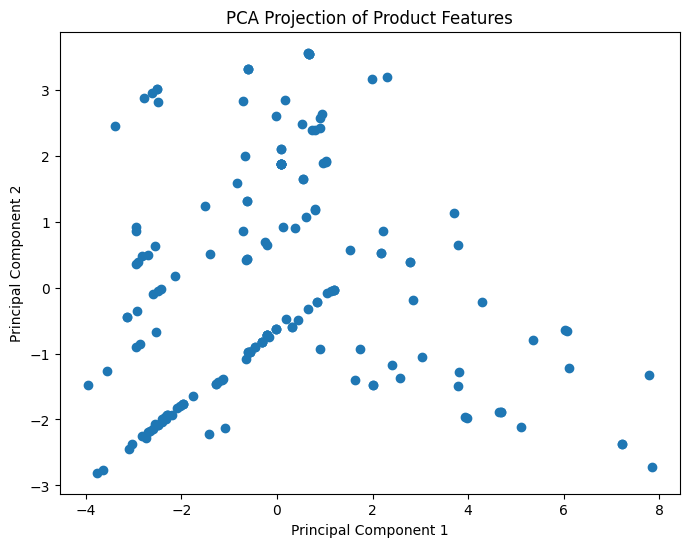

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1])
plt.title('PCA Projection of Product Features')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

---
## F. Save Datasets

> Do not change this code

In [64]:
# DO NOT MODIFY THE CODE IN THIS CELL
try:
    X_train.to_csv(at.folder_path / 'X_train.csv', index=False)
    X_val.to_csv(at.folder_path   / 'X_val.csv',   index=False)
    X_test.to_csv(at.folder_path  / 'X_test.csv',  index=False)
    print('Datasets saved successfully.')
except Exception as e:
    print(e)

Datasets saved successfully.
